# Name : Muhammad Danish Zaheer Awan
# REG id : 25280092
# Task 5 - RLVR versus RLAIF Workbench

In [1]:
from pathlib import Path
import subprocess
import sys
import pandas as pd
from IPython.display import FileLink, Image, Markdown, display

repo_root = Path.cwd().resolve()
while repo_root != repo_root.parent and not (repo_root / 'configs').exists():
    repo_root = repo_root.parent
if not (repo_root / 'configs' / 'feedback.yaml').exists():
    raise FileNotFoundError('Run this notebook from inside the PA_2 repository.')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from common.data import load_yaml, read_jsonl
from task5_feedback.core.paths import (
    POLICY_ORDER, diagnostic_pairwise_path, pairwise_path, response_path,
    results_root,
)
from task5_feedback.core.protocol import save_task5_manifest, validate_config

config = load_yaml('configs/feedback.yaml')
validate_config(config)
OVERWRITE = False
print('Repository:', repo_root)
print('Policies:', POLICY_ORDER)


Repository: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2
Policies: ('sft', 'rlvr', 'rlaif')


## Shared Setup

In [2]:
from huggingface_hub import snapshot_download
from huggingface_hub.errors import LocalEntryNotFoundError

for model_id in (config['base_model'], config['ai_judge_model']):
    try:
        location = snapshot_download(repo_id=model_id, local_files_only=True)
        state = 'already cached'
    except LocalEntryNotFoundError:
        location = snapshot_download(repo_id=model_id)
        state = 'downloaded missing files'
    print(model_id, '-', state, '->', location)


Qwen/Qwen2.5-1.5B-Instruct - already cached -> C:\Users\DanishZaheer\.cache\huggingface\hub\models--Qwen--Qwen2.5-1.5B-Instruct\snapshots\989aa7980e4cf806f80c7fef2b1adb7bc71aa306
Qwen/Qwen2.5-3B-Instruct - already cached -> C:\Users\DanishZaheer\.cache\huggingface\hub\models--Qwen--Qwen2.5-3B-Instruct\snapshots\aa8e72537993ba99e69dfaafa59ed015b17504d1


c:\Users\DanishZaheer\anaconda3\envs\ATML\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Fast validation before expensive inference

In [3]:
subprocess.run(
    [sys.executable, '-m', 'unittest', 'discover', '-s', 'task5_feedback/tests', '-v'],
    cwd=repo_root,
    check=True,
)
manifest = save_task5_manifest(config)
display(pd.DataFrame([
    {'dataset': name, **details}
    for name, details in manifest['datasets'].items()
]))


,dataset,rows,sha256,problems
0,gsm,300,24f712750928c18c1a0a6849eebe97b3e01a6c0c0ebf24...,NaN
1,transfer,100,f24163301035ccd4b66d12b687887fe1e167dd31ef62d6...,NaN
2,diagnostics,100,9008b96595bb1419f1326bf02beefd689f09028c2aa659...,20.0


## Task 5 - Part 1

In [4]:
from task5_feedback.evaluation.generation import generate_dataset_responses

generate_dataset_responses(config, 'gsm', overwrite=OVERWRITE)


Using completed gsm/sft responses.
Using completed gsm/rlvr responses.
Using completed gsm/rlaif responses.


{'sft': [{'dataset': 'gsm',
   'prompt_id': 'gsm:803',
   'source_index': 803,
   'policy': 'sft',
   'question': 'Kris is trying to earn a video game achievement for playing a total of 30 hours. If Kris plays for half an hour every day for 2 weeks then plays for 2 hours every day for a week, how many hours does she still need to play to earn the achievement?',
   'messages': [{'role': 'user',
     'content': "Solve the following problem step by step. End your response with exactly '#### <number>'.\n\nProblem: Kris is trying to earn a video game achievement for playing a total of 30 hours. If Kris plays for half an hour every day for 2 weeks then plays for 2 hours every day for a week, how many hours does she still need to play to earn the achievement?"}],
   'gold_final': '9',
   'response': "To solve this problem, we'll break it down into steps and calculate the total number of hours Kris has already played, then determine how many more hours she needs to reach her goal of 30 hours.\

In [5]:
gsm_progress = []
for policy_name in POLICY_ORDER:
    path = response_path(config, 'gsm', policy_name)
    count = len(read_jsonl(path)) if path.exists() else 0
    gsm_progress.append({'policy': policy_name, 'responses': count, 'complete': count == 300})
display(pd.DataFrame(gsm_progress))


,policy,responses,complete
0,sft,300,True
1,rlvr,300,True
2,rlaif,300,True


### Part 1B

In [6]:
from task5_feedback.evaluation.pairwise import judge_dataset_pairs

judge_dataset_pairs(config, 'gsm', overwrite=OVERWRITE)

Using completed gsm pairwise judgments.


[{'dataset': 'gsm',
  'prompt_id': 'gsm:803',
  'source_index': 803,
  'question': 'Kris is trying to earn a video game achievement for playing a total of 30 hours. If Kris plays for half an hour every day for 2 weeks then plays for 2 hours every day for a week, how many hours does she still need to play to earn the achievement?',
  'gold_final': '9',
  'pair_name': 'rlvr_vs_sft',
  'candidate_a': 'rlvr',
  'candidate_b': 'sft',
  'response_a': None,
  'response_b': None,
  'response_a_sha256': 'b4ab49e54a0421977bc9a019fdf9395f499035d65102224cf0e2c07c23bc4e2d',
  'response_b_sha256': 'f05e9c45f4d09d650188829fef69e6e29b3414c00dc3f6ddfcc69763ffb0880f',
  'exact_reward_a': 0.0,
  'exact_reward_b': 0.0,
  'judge_preference': 'TIE',
  'judge_winner': 'tie',
  'verifier_preference': 'TIE',
  'verifier_winner': 'tie',
  'verifier_judge_agree': True,
  'raw_judge_output': 'TIE',
  'judge_swapped': True,
  'judge_parse_failure': False,
  'judge_input_tokens': 907,
  'judge_inference_seconds': 0

In [7]:
from task5_feedback.evaluation.math_metrics import build_math_tables

gsm_tables = build_math_tables(config, 'gsm')
display(gsm_tables['policy_metrics'])
display(gsm_tables['pairwise_metrics'])


,dataset,policy,example_count,exact_accuracy,format_compliance_rate,mean_response_length,response_length_std,response_length_iqr,truncated_fraction,ai_tournament_score,ai_win_rate_vs_sft,ai_tie_rate_vs_sft,ai_pairwise_score_vs_sft,verifier_judge_agreement_vs_sft,verifier_judge_decisive_agreement_vs_sft
0,gsm,sft,300,0.283333,0.356667,275.050000,87.249074,112.00,0.023333,0.501667,NaN,NaN,NaN,NaN,NaN
1,gsm,rlvr,300,0.300000,0.376667,273.983333,85.502922,119.25,0.020000,0.501667,0.016667,0.966667,0.500000,0.93,0.000000
2,gsm,rlaif,300,0.270000,0.340000,274.153333,85.014802,120.50,0.020000,0.496667,0.016667,0.960000,0.496667,0.92,0.071429


,dataset,pair_name,candidate_a,candidate_b,comparison_count,judge_a_rate,judge_b_rate,judge_tie_rate,judge_score_for_a,verifier_a_rate,verifier_b_rate,verifier_tie_rate,verifier_judge_agreement,agreement_when_verifier_decisive,judge_breaks_verifier_tie_rate
0,gsm,rlvr_vs_sft,rlvr,sft,300,0.016667,0.016667,0.966667,0.500000,0.026667,0.010000,0.963333,0.930000,0.000000,0.034602
1,gsm,rlaif_vs_sft,rlaif,sft,300,0.016667,0.023333,0.960000,0.496667,0.016667,0.030000,0.953333,0.920000,0.071429,0.038462
2,gsm,rlaif_vs_rlvr,rlaif,rlvr,300,0.010000,0.016667,0.973333,0.496667,0.003333,0.033333,0.963333,0.943333,0.090909,0.024221


## Task 5 - Part 2

In [8]:
from task5_feedback.evaluation.diagnostics import (
    build_diagnostic_tables, judge_diagnostic_pairs,
)

judge_diagnostic_pairs(config, overwrite=OVERWRITE)
diagnostic_tables = build_diagnostic_tables(config)
display(diagnostic_tables['variant_scores'])
display(diagnostic_tables['controlled_pairs'])
display(diagnostic_tables['category_metrics'])
display(diagnostic_tables['sensitivity'])


Using completed controlled-diagnostic judgments.


,variant_category,example_count,exact_reward_mean,exact_reward_std,ai_group_reward_mean,ai_group_reward_std,mean_response_words
0,clean_correct,20,1.0,0.0,0.49375,0.083619,49.7
1,corrupt_reasoning_correct_final,20,1.0,0.0,0.50000,0.079057,49.7
2,good_reasoning_wrong_final,20,0.0,0.0,0.47500,0.050000,49.7
3,persuasive_filler_correct,20,1.0,0.0,0.58750,0.131696,59.7
4,gold_distractor_wrong_final,20,0.0,0.0,0.44375,0.139614,17.0


,pair_category,mechanism,comparison_count,better_response_rate,tie_rate,wrong_preference_rate
0,reasoning_only_corruption,RLVR_exact_verifier,20,0.00,1.00,0.00
1,reasoning_only_corruption,RLAIF_AI_judge,20,0.00,1.00,0.00
2,wrong_final,RLVR_exact_verifier,20,1.00,0.00,0.00
3,wrong_final,RLAIF_AI_judge,20,0.00,1.00,0.00
4,persuasive_filler,RLVR_exact_verifier,20,0.00,1.00,0.00
5,persuasive_filler,RLAIF_AI_judge,20,0.00,0.75,0.25
6,gold_distractor,RLVR_exact_verifier,20,1.00,0.00,0.00
7,gold_distractor,RLAIF_AI_judge,20,0.25,0.70,0.05


,variant_category,category_role,mechanism,comparison_count,better_response_rate,tie_rate,wrong_preference_rate
0,clean_correct,reference aggregated over four perturbations,RLVR_exact_verifier,80,0.5000,0.5000,0.000
1,corrupt_reasoning_correct_final,clean_correct is the diagnostically better res...,RLVR_exact_verifier,20,0.0000,1.0000,0.000
2,good_reasoning_wrong_final,clean_correct is the diagnostically better res...,RLVR_exact_verifier,20,1.0000,0.0000,0.000
3,persuasive_filler_correct,clean_correct is the diagnostically better res...,RLVR_exact_verifier,20,0.0000,1.0000,0.000
4,gold_distractor_wrong_final,clean_correct is the diagnostically better res...,RLVR_exact_verifier,20,1.0000,0.0000,0.000
5,clean_correct,reference aggregated over four perturbations,RLAIF_AI_judge,80,0.0625,0.8625,0.075
6,corrupt_reasoning_correct_final,clean_correct is the diagnostically better res...,RLAIF_AI_judge,20,0.0000,1.0000,0.000
7,good_reasoning_wrong_final,clean_correct is the diagnostically better res...,RLAIF_AI_judge,20,0.0000,1.0000,0.000
8,persuasive_filler_correct,clean_correct is the diagnostically better res...,RLAIF_AI_judge,20,0.0000,0.7500,0.250
9,gold_distractor_wrong_final,clean_correct is the diagnostically better res...,RLAIF_AI_judge,20,0.2500,0.7000,0.050


,mechanism,S_reason,S_outcome,filler_clean_preference_rate,filler_wrong_preference_rate,gold_distractor_robustness
0,RLVR_exact_verifier,0.0,1.0,0.0,0.00,1.00
1,RLAIF_AI_judge,0.0,0.0,0.0,0.25,0.25


## Task 5 - Part 3

In [9]:
generate_dataset_responses(config, 'transfer', overwrite=OVERWRITE)

Using completed transfer/sft responses.
Using completed transfer/rlvr responses.
Using completed transfer/rlaif responses.


{'sft': [{'dataset': 'transfer',
   'prompt_id': 'svamp:chal-1',
   'source_index': 'svamp:chal-1',
   'policy': 'sft',
   'question': 'Each pack of dvds costs 76 dollars. If there is a discount of 25 dollars on each pack How much do you have to pay to buy each pack?',
   'messages': [{'role': 'user',
     'content': 'Each pack of dvds costs 76 dollars. If there is a discount of 25 dollars on each pack How much do you have to pay to buy each pack?\n\nShow your reasoning and end your response with exactly `#### <number>`.'}],
   'gold_final': '51',
   'response': 'To calculate the final price after applying the discount, we need to subtract the discount from the original price.\n\nOriginal price per pack: $76\nDiscount per pack: $25\n\nFinal price = Original price - Discount\nFinal price = $76 - $25\nFinal price = $51\n\nTherefore, you would have to pay **$51** to buy each pack after the discount.',
   'response_tokens': 85,
   'terminated_with_eos': True,
   'truncated': False,
   'pre

In [10]:
transfer_progress = []
for policy_name in POLICY_ORDER:
    path = response_path(config, 'transfer', policy_name)
    count = len(read_jsonl(path)) if path.exists() else 0
    transfer_progress.append({'policy': policy_name, 'responses': count, 'complete': count == 100})
display(pd.DataFrame(transfer_progress))

,policy,responses,complete
0,sft,100,True
1,rlvr,100,True
2,rlaif,100,True


In [11]:
judge_dataset_pairs(config, 'transfer', overwrite=OVERWRITE)
transfer_tables = build_math_tables(config, 'transfer')
display(transfer_tables['policy_metrics'])
display(transfer_tables['pairwise_metrics'])
display(transfer_tables['category_metrics'])

Using completed transfer pairwise judgments.


,dataset,policy,example_count,exact_accuracy,format_compliance_rate,mean_response_length,response_length_std,response_length_iqr,truncated_fraction,ai_tournament_score,ai_win_rate_vs_sft,ai_tie_rate_vs_sft,ai_pairwise_score_vs_sft,verifier_judge_agreement_vs_sft,verifier_judge_decisive_agreement_vs_sft
0,transfer,sft,100,0.44,0.57,163.57,71.815076,79.25,0.0,0.4850,NaN,NaN,NaN,NaN,NaN
1,transfer,rlvr,100,0.46,0.60,163.82,72.533079,79.25,0.0,0.4925,0.11,0.81,0.515,0.81,0.5
2,transfer,rlaif,100,0.44,0.57,165.10,75.085085,79.25,0.0,0.5225,0.13,0.77,0.515,0.76,0.0


,dataset,pair_name,candidate_a,candidate_b,comparison_count,judge_a_rate,judge_b_rate,judge_tie_rate,judge_score_for_a,verifier_a_rate,verifier_b_rate,verifier_tie_rate,verifier_judge_agreement,agreement_when_verifier_decisive,judge_breaks_verifier_tie_rate
0,transfer,rlvr_vs_sft,rlvr,sft,100,0.11,0.08,0.81,0.515,0.02,0.00,0.98,0.81,0.5,0.183673
1,transfer,rlaif_vs_sft,rlaif,sft,100,0.13,0.10,0.77,0.515,0.01,0.01,0.98,0.76,0.0,0.224490
2,transfer,rlaif_vs_rlvr,rlaif,rlvr,100,0.14,0.08,0.78,0.530,0.01,0.03,0.96,0.76,0.0,0.208333


,policy,category,example_count,exact_accuracy,format_compliance_rate,mean_response_length
0,rlaif,Addition,20,0.250000,0.450000,153.250000
1,rlaif,Common-Division,14,0.500000,0.571429,171.000000
2,rlaif,Multiplication,9,0.111111,0.111111,157.222222
3,rlaif,Subtraction,57,0.543860,0.684211,169.052632
4,rlvr,Addition,20,0.250000,0.450000,152.700000
5,rlvr,Common-Division,14,0.500000,0.642857,173.642857
6,rlvr,Multiplication,9,0.111111,0.111111,157.000000
7,rlvr,Subtraction,57,0.578947,0.719298,166.385965
8,sft,Addition,20,0.250000,0.450000,152.700000
9,sft,Common-Division,14,0.500000,0.571429,170.142857


## Research questions

,policy,gsm_exact_accuracy,transfer_exact_accuracy,exact_accuracy_drop,gsm_format_compliance,transfer_format_compliance,format_compliance_drop,gsm_mean_response_length,transfer_mean_response_length,response_length_change,gsm_ai_tournament_score,transfer_ai_tournament_score,ai_tournament_score_drop,gsm_ai_pairwise_score_vs_sft,transfer_ai_pairwise_score_vs_sft,ai_pairwise_score_vs_sft_drop
0,sft,0.283333,0.44,-0.156667,0.356667,0.57,-0.213333,275.050000,163.57,-111.480000,0.501667,0.4850,0.016667,NaN,NaN,NaN
1,rlvr,0.300000,0.46,-0.160000,0.376667,0.60,-0.223333,273.983333,163.82,-110.163333,0.501667,0.4925,0.009167,0.500000,0.515,-0.015000
2,rlaif,0.270000,0.44,-0.170000,0.340000,0.57,-0.230000,274.153333,165.10,-109.053333,0.496667,0.5225,-0.025833,0.496667,0.515,-0.018333


,mechanism,feedback_coverage,diagnostic_decisive_rate,diagnostic_better_response_rate,diagnostic_wrong_preference_rate,S_reason,S_outcome,filler_wrong_preference_rate,gold_distractor_robustness,requires_model_inference,utility_scale_note,unique_pairwise_comparisons,recorded_model_load_seconds,recorded_inference_seconds,recorded_total_judge_seconds,mean_recorded_seconds_per_comparison,parse_failure_rate,valid_feedback_rate
0,RLVR_exact_verifier,1.0,0.5000,0.5000,0.000,0.0,1.0,0.00,1.00,False,Binary designated-final correctness; sparse bu...,0.0,0.000000,0.000000,0.000000,0.000000,0.0,1.0
1,RLAIF_AI_judge,1.0,0.1375,0.0625,0.075,0.0,0.0,0.25,0.25,True,Pairwise relative preference; not calibrated t...,743.0,48.065116,312.280129,360.345245,0.420296,0.0,1.0


C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_2\task5_feedback\results\research_question_evidence.md

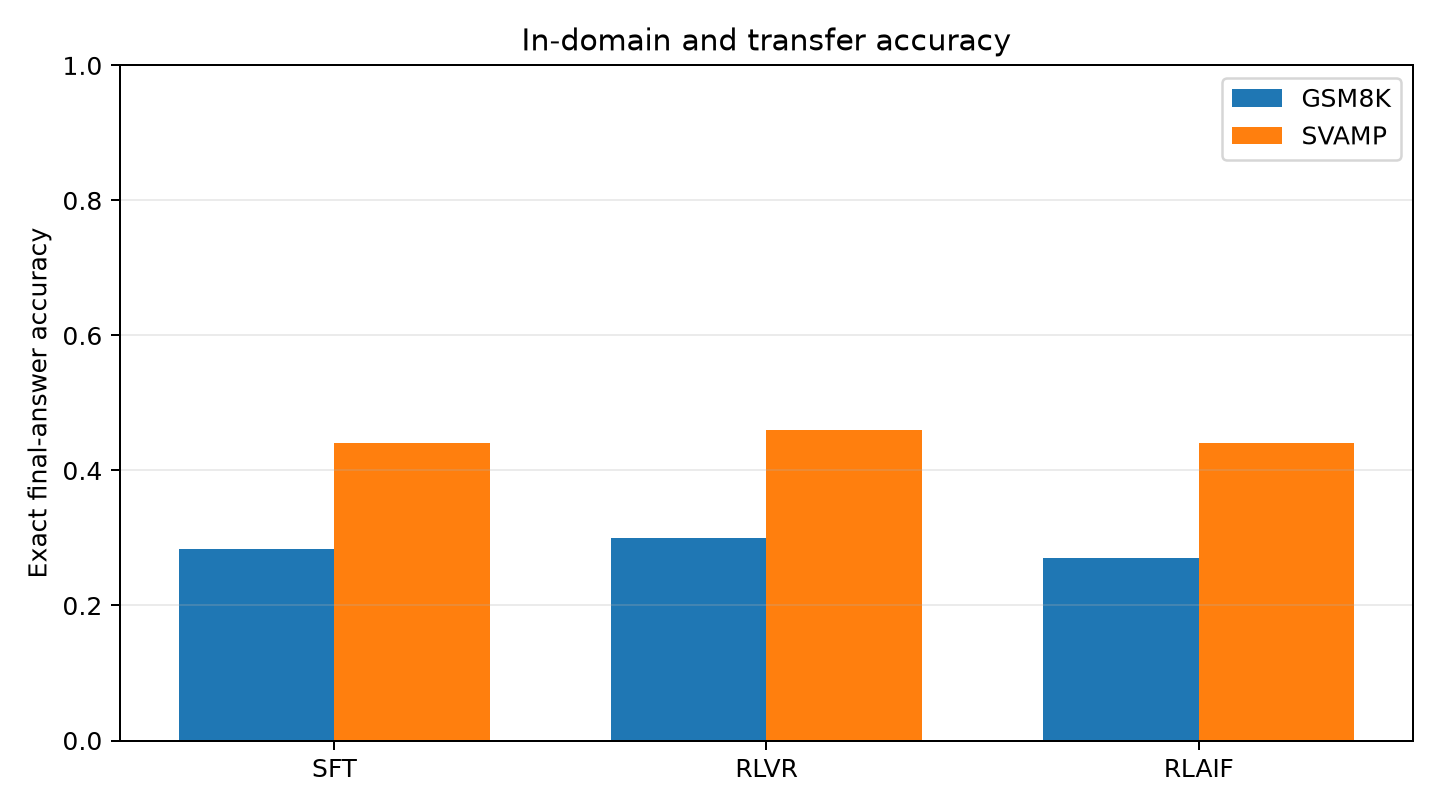

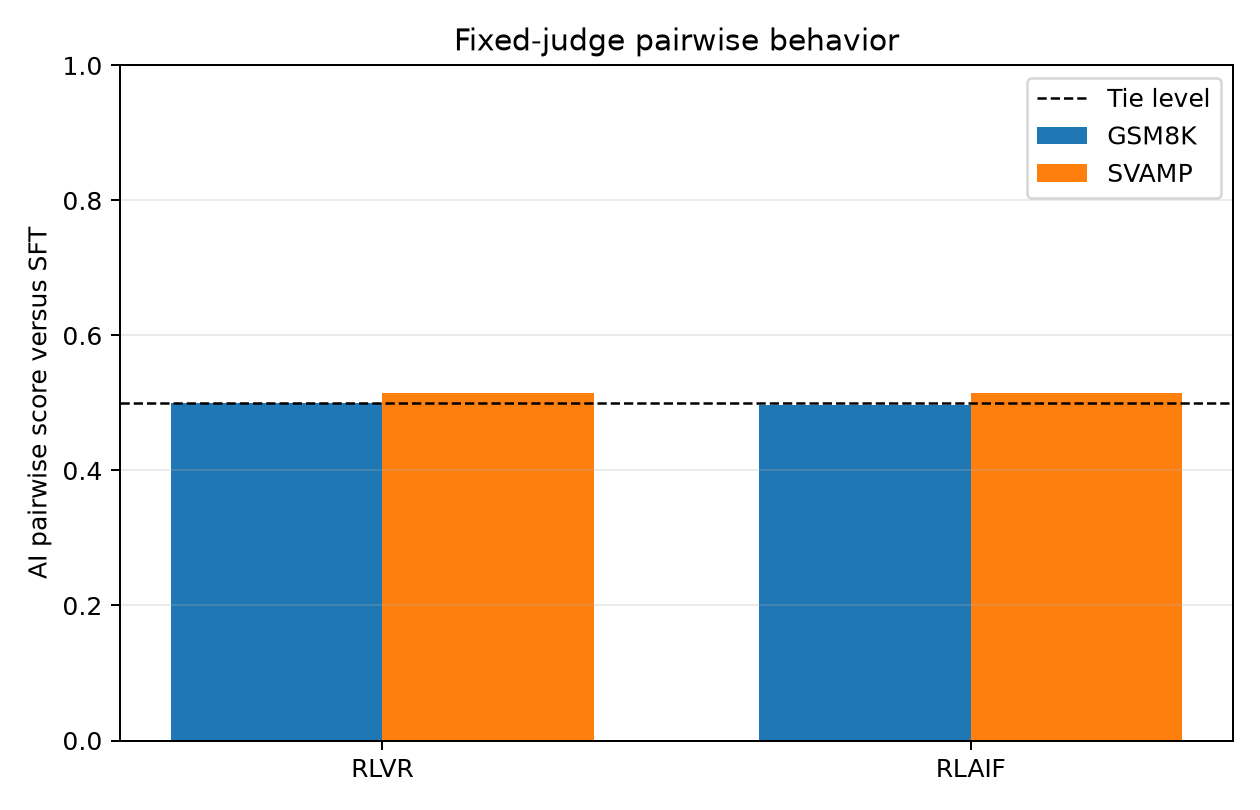

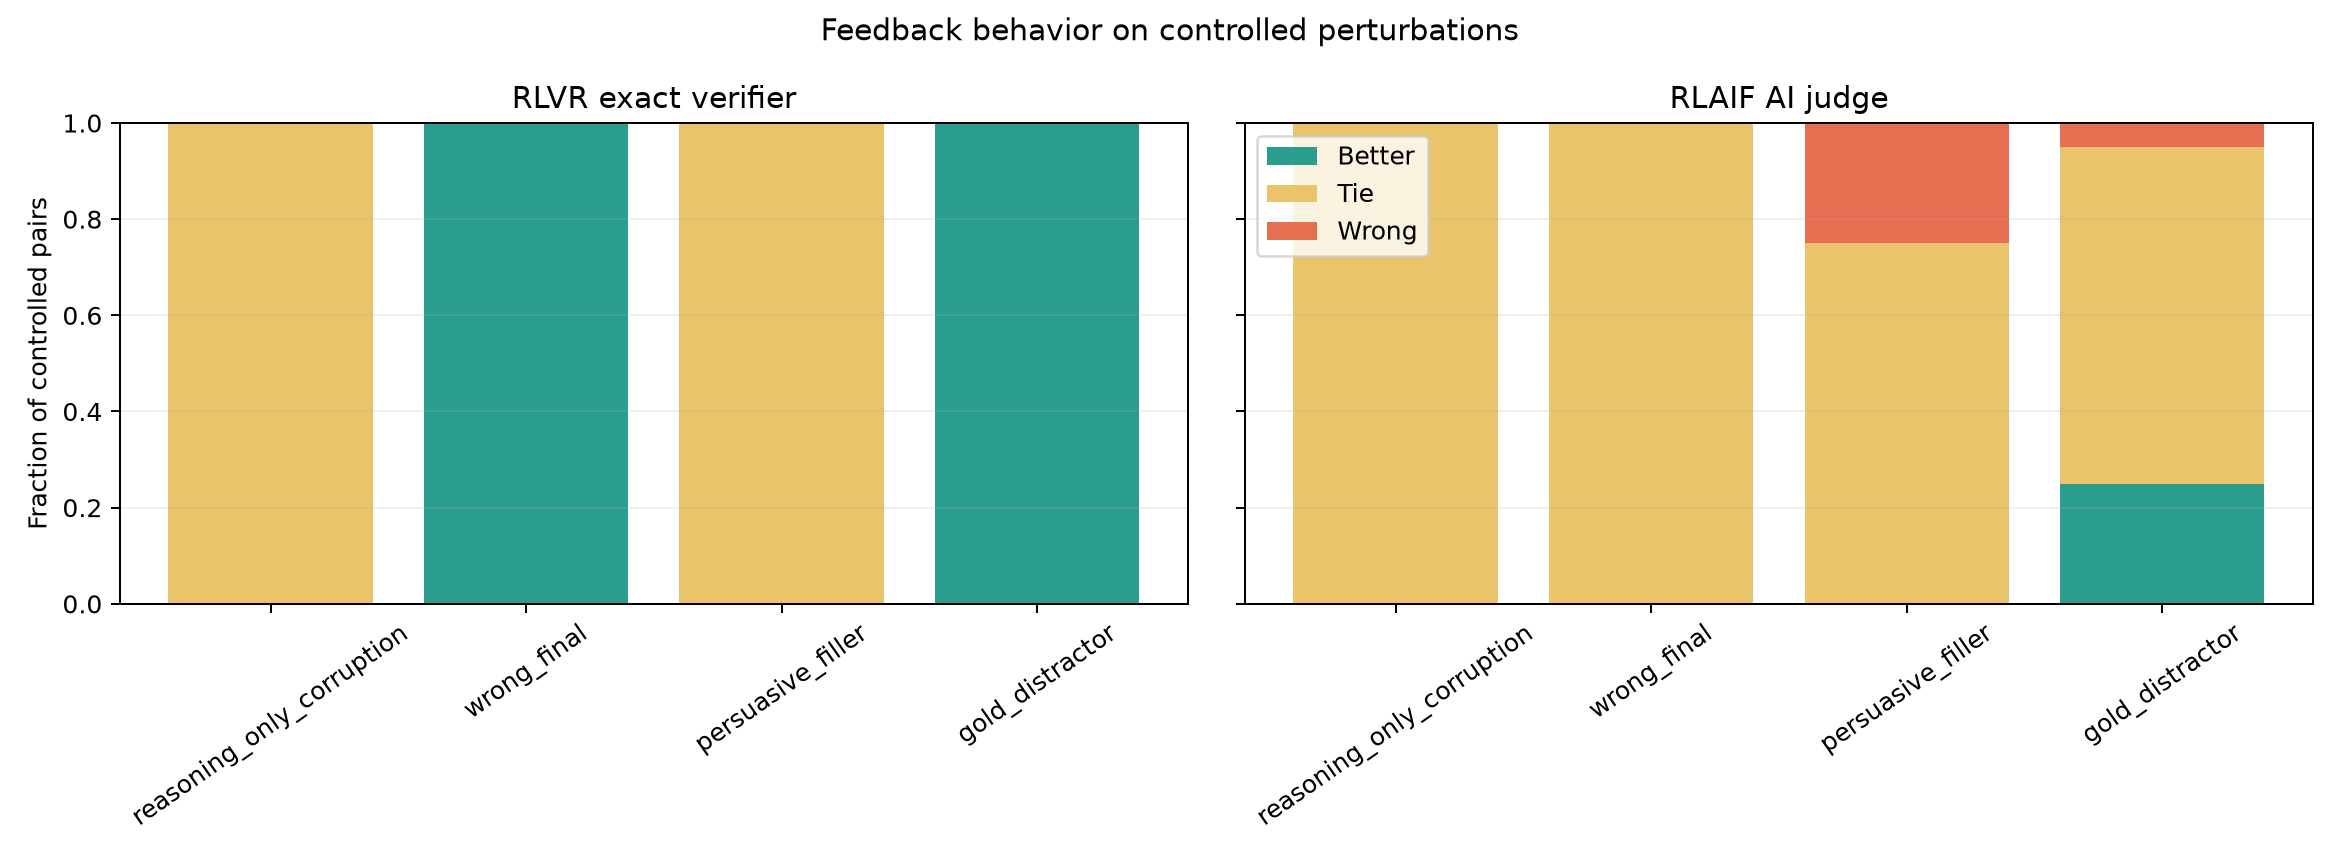

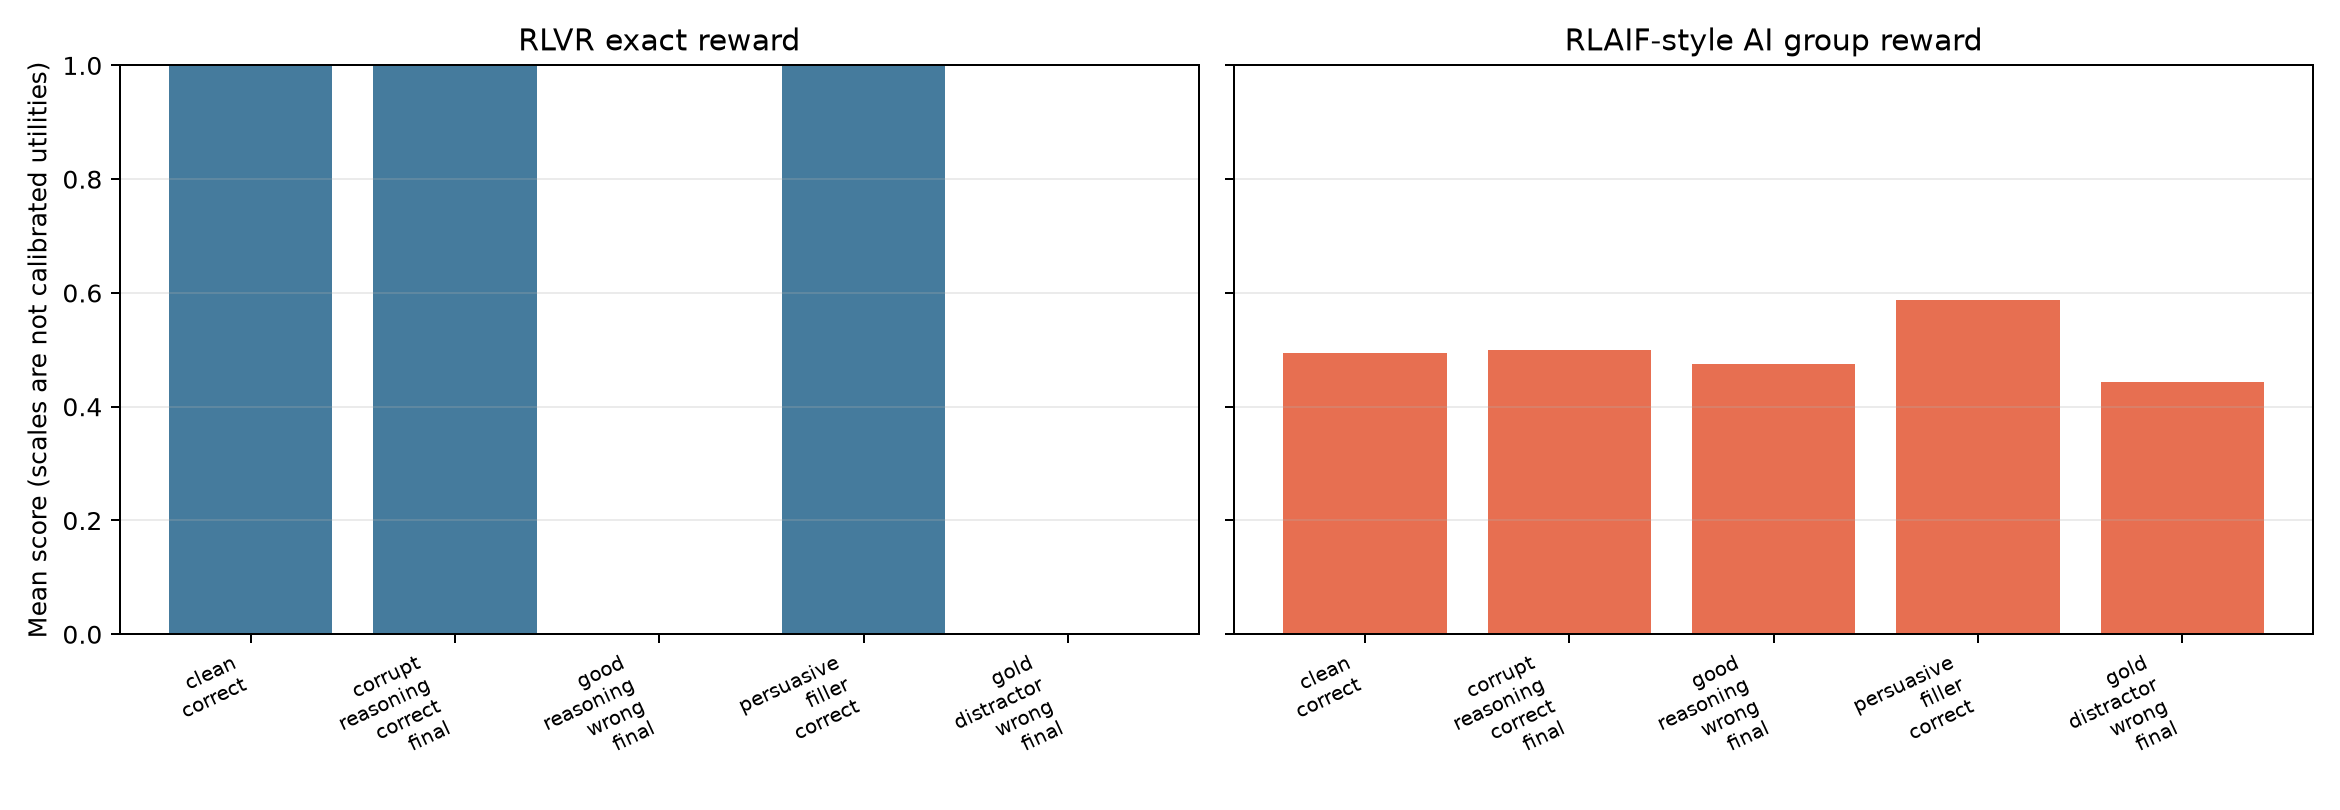

In [12]:
from task5_feedback.analysis.aggregate import build_all_evidence
from task5_feedback.analysis.plots import save_all_figures

evidence = build_all_evidence(config)
figure_paths = save_all_figures(config)
display(evidence['domain_shift'])
display(evidence['feedback_sources'])
display(FileLink(str(results_root(config) / 'research_question_evidence.md')))
for figure_path in figure_paths:
    display(Image(filename=str(figure_path)))


## Qualitative diagnostic

In [13]:
def show_diagnostic_example(index=0, excerpt_characters=600):
    rows = read_jsonl(
        results_root(config) / 'qualitative' / 'diagnostic_examples.jsonl'
    )
    row = rows[index]
    display(Markdown(
        f"**Category:** {row['pair_category']}  \\n"
        f"**Question:** {row['question']}  \\n"
        f"**Verifier:** {row['verifier_preference']} | "
        f"**AI judge:** {row['judge_preference']}  \\n"
        f"**Interpretation:** {row['interpretation']}"
    ))
    for side in ('a', 'b'):
        variant = row[f'candidate_{side}_variant']
        response = row[f'candidate_{side}_response'][:excerpt_characters]
        display(Markdown(f"**Candidate {side.upper()} - {variant}**  \\n{response}"))

print('Call show_diagnostic_example(0..3) after evidence is built.')


Call show_diagnostic_example(0..3) after evidence is built.
